1.-Importar las herramientas

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Herramientas cargadas correctamente")

Herramientas cargadas correctamente


2.-Crear un conjunto de datos de ejemplo

In [4]:
datos = pd.DataFrame({
    "fecha": [
        "2026-10-01", "2026-10-02", "2026-10-03",
        "2026-10-03", "2026-10-04", "2026-10-05",
        "2026-10-06", "2026-10-07"
    ],
    "peso_total_kg": [22.5, 22.0, 21.6, 21.6, 21.2, None, 20.4, 11.0],
    "tara_kg": [12.5, 12.5, 12.5, 12.5, 12.5, 12.5, 12.5, 12.5],
    "temperatura": [25, 26, 24, 24, 27, 26, 25, 25]
})

display(datos)

,fecha,peso_total_kg,tara_kg,temperatura
0,2026-10-01,22.5,12.5,25
1,2026-10-02,22.0,12.5,26
2,2026-10-03,21.6,12.5,24
3,2026-10-03,21.6,12.5,24
4,2026-10-04,21.2,12.5,27
5,2026-10-05,NaN,12.5,26
6,2026-10-06,20.4,12.5,25
7,2026-10-07,11.0,12.5,25


3.-Inspeccionar los dato.

In [5]:
print("Cantidad de filas y columnas:", datos.shape)

print("\nTipos de datos:")
print(datos.dtypes)

print("\nValores faltantes:")
print(datos.isnull().sum())

print("\nRegistros duplicados:")
print(datos.duplicated().sum())

print("\nResumen estadístico:")
display(datos.describe())

Cantidad de filas y columnas: (8, 4)

Tipos de datos:
fecha             object
peso_total_kg    float64
tara_kg          float64
temperatura        int64
dtype: object

Valores faltantes:
fecha            0
peso_total_kg    1
tara_kg          0
temperatura      0
dtype: int64

Registros duplicados:
1

Resumen estadístico:


,peso_total_kg,tara_kg,temperatura
count,7.000000,8.0,8.000000
mean,20.042857,12.5,25.250000
std,4.040568,0.0,1.035098
min,11.000000,12.5,24.000000
25%,20.800000,12.5,24.750000
50%,21.600000,12.5,25.000000
75%,21.800000,12.5,26.000000
max,22.500000,12.5,27.000000


4.-Limpiar los datos

In [6]:
limpios = datos.copy()

# 1. Eliminar registros completamente duplicados
limpios = limpios.drop_duplicates().copy()

# 2. Convertir la fecha al formato correcto
limpios["fecha"] = pd.to_datetime(
    limpios["fecha"], errors="coerce"
)

# 3. Convertir las columnas numéricas
columnas_numericas = [
    "peso_total_kg", "tara_kg", "temperatura"
]

for columna in columnas_numericas:
    limpios[columna] = pd.to_numeric(
        limpios[columna], errors="coerce"
)

# Limpiar los valores nulos en peso_total_kg (por ejemplo, mediante interpolación)
limpios["peso_total_kg"] = limpios["peso_total_kg"].interpolate(method="linear")

# 4. Marcar si originalmente había mediciones faltantes
limpios["peso_faltante"] = (
    datos["peso_total_kg"].isna()
)

# 5. Verificar si el peso total es compatible con la tara
limpios["peso_valido"] = (
    limpios["peso_total_kg"].notna()
    & limpios["tara_kg"].notna()
    & (limpios["peso_total_kg"] >= limpios["tara_kg"])
)

display(limpios)

,fecha,peso_total_kg,tara_kg,temperatura,peso_faltante,peso_valido
0,2026-10-01,22.5,12.5,25,False,True
1,2026-10-02,22.0,12.5,26,False,True
2,2026-10-03,21.6,12.5,24,False,True
4,2026-10-04,21.2,12.5,27,False,True
5,2026-10-05,20.8,12.5,26,True,True
6,2026-10-06,20.4,12.5,25,False,True
7,2026-10-07,11.0,12.5,25,False,False


5.- Transformar los datos

In [7]:
# Calcular los kg de gas solamente cuando la medición es válida
limpios["gas_restante_kg"] = np.where(
    limpios["peso_valido"],
    limpios["peso_total_kg"] - limpios["tara_kg"],
    np.nan
)

# Calcular el porcentaje de gas restante
CAPACIDAD_GAS_KG = 10

limpios["nivel_gas_pct"] = (
    limpios["gas_restante_kg"] / CAPACIDAD_GAS_KG * 100
).clip(upper=100)

# Crear una columna con el día de la semana
limpios["dia_semana"] = (
    limpios["fecha"].dt.day_name()
)

# Clasificar el nivel de gas
limpios["estado_gas"] = np.select(
    [
        limpios["nivel_gas_pct"].isna(),
        limpios["nivel_gas_pct"] <= 20
    ],
    [
        "Sin datos válidos",
        "Nivel bajo"
    ],
    default="Nivel normal"
)

display(limpios)

,fecha,peso_total_kg,tara_kg,temperatura,peso_faltante,peso_valido,gas_restante_kg,nivel_gas_pct,dia_semana,estado_gas
0,2026-10-01,22.5,12.5,25,False,True,10.0,100.0,Thursday,Nivel normal
1,2026-10-02,22.0,12.5,26,False,True,9.5,95.0,Friday,Nivel normal
2,2026-10-03,21.6,12.5,24,False,True,9.1,91.0,Saturday,Nivel normal
4,2026-10-04,21.2,12.5,27,False,True,8.7,87.0,Sunday,Nivel normal
5,2026-10-05,20.8,12.5,26,True,True,8.3,83.0,Monday,Nivel normal
6,2026-10-06,20.4,12.5,25,False,True,7.9,79.0,Tuesday,Nivel normal
7,2026-10-07,11.0,12.5,25,False,False,NaN,NaN,Wednesday,Sin datos válidos


6.- Preparar la tabla final

In [8]:
datos_validos = limpios[
    limpios["peso_valido"]
    & limpios["fecha"].notna()
].copy()

columnas_finales = [
    "fecha",
    "peso_total_kg",
    "tara_kg",
    "gas_restante_kg",
    "nivel_gas_pct",
    "temperatura",
    "dia_semana",
    "estado_gas"
]

tabla_final = datos_validos[columnas_finales]

print("Registros originales:", len(datos))
print("Registros después de eliminar duplicados:", len(limpios))
print("Registros válidos para analizar:", len(tabla_final))
print("Registros excluidos del análisis:", len(limpios) - len(tabla_final))

display(tabla_final)

Registros originales: 8
Registros después de eliminar duplicados: 7
Registros válidos para analizar: 6
Registros excluidos del análisis: 1


,fecha,peso_total_kg,tara_kg,gas_restante_kg,nivel_gas_pct,temperatura,dia_semana,estado_gas
0,2026-10-01,22.5,12.5,10.0,100.0,25,Thursday,Nivel normal
1,2026-10-02,22.0,12.5,9.5,95.0,26,Friday,Nivel normal
2,2026-10-03,21.6,12.5,9.1,91.0,24,Saturday,Nivel normal
4,2026-10-04,21.2,12.5,8.7,87.0,27,Sunday,Nivel normal
5,2026-10-05,20.8,12.5,8.3,83.0,26,Monday,Nivel normal
6,2026-10-06,20.4,12.5,7.9,79.0,25,Tuesday,Nivel normal


7.- Analizar y visualizar los resultados

Promedio de gas restante (kg): 8.92
Promedio del nivel de gas (%): 89.17


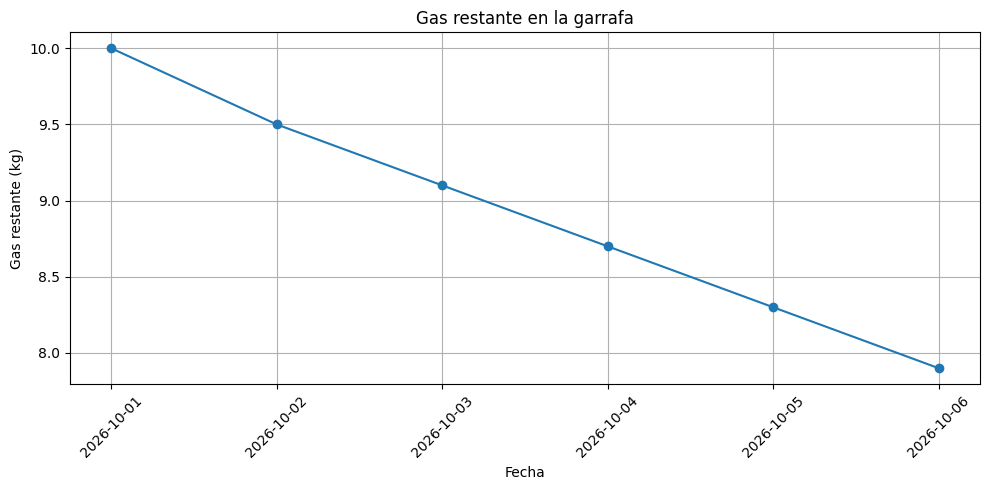

In [9]:
print("Promedio de gas restante (kg):",
      round(tabla_final["gas_restante_kg"].mean(), 2))

print("Promedio del nivel de gas (%):",
      round(tabla_final["nivel_gas_pct"].mean(), 2))

plt.figure(figsize=(10, 5))

plt.plot(
    tabla_final["fecha"],
    tabla_final["gas_restante_kg"],
    marker="o"
)

plt.title("Gas restante en la garrafa")
plt.xlabel("Fecha")
plt.ylabel("Gas restante (kg)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

8.- Exportar los datos limpios

In [10]:
tabla_final.to_csv(
    "GasApp_Datos_Limpios.csv",
    index=False
)

print("Archivo CSV generado correctamente")

Archivo CSV generado correctamente


9.- Datos limpios guardados

In [11]:
from google.colab import files

files.download("GasApp_Datos_Limpios.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>